# JOSCEX — Pipeline Kanonik Final (Tokopedia Sentiment Classification)

**Tujuan notebook ini:** satu sumber kebenaran (single source of truth) untuk semua angka di manuskrip revisi — menggantikan run-run terpisah sebelumnya yang saling bertentangan.

**Aturan wajib:**
1. Selalu `Runtime > Restart runtime` sebelum `Run all` — jangan pernah edit & run sel di tengah tanpa restart.
2. Semua proses acak menggunakan `RANDOM_STATE` tunggal dari Cell 2 — jangan override di sel manapun.
3. Semua tabel output disimpan ke folder `/content/final_results/` dengan nama tetap (tanpa suffix versi `_v2`, `_v3`, dst).
4. Jalankan top-to-bottom secara linear, satu kali penuh, sebelum mengambil angka mana pun untuk manuskrip.

**Struktur:**
- Fase 0: Setup, data, preprocessing (negation-preserving stopwords)
- Fase 1: Feature engineering Config A/B/C
- Fase 2: Baseline models (tanpa SMOTE)
- Fase 3: SMOTE + GridSearchCV tuning (single split) — Table 3
- Fase 4: Perbandingan model tambahan (LightGBM, RandomForest, CatBoost, SVM)
- Fase 5: Repeated Stratified K-Fold — evaluasi robust
- Fase 6: Uji signifikansi statistik berpasangan
- Fase 7: Feature importance (top-20) — Table 5
- Fase 8: Varian SMOTE (Borderline, SMOTE-Tomek, SVM-SMOTE)
- Fase 9: Analisis dimensionalitas & jarak k-NN
- Fase 10: Eksplorasi n-gram
- Fase 11: Confusion matrix & figure final
- Fase 12: Konsolidasi & unduh semua tabel final


## Fase 0.1 — Instalasi & Import

In [4]:
!pip install -q xgboost lightgbm catboost imbalanced-learn scikit-learn scipy matplotlib seaborn Sastrawi

import re
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
# PENTING: pakai Pipeline dari imblearn, BUKAN sklearn.pipeline.Pipeline.
# sklearn.pipeline.Pipeline mensyaratkan setiap step punya fit_transform,
# sedangkan SMOTE/BorderlineSMOTE/SMOTETomek/SVMSMOTE hanya punya fit_resample.
# Memakai sklearn.pipeline.Pipeline dengan step SMOTE akan gagal dengan:
#   TypeError: All intermediate steps should be transformers ... 'SMOTE' doesn't
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, recall_score, precision_score, f1_score,
    accuracy_score, ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE, BorderlineSMOTE, SVMSMOTE
from imblearn.combine import SMOTETomek

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

from scipy.stats import wilcoxon, ttest_rel
from scipy.spatial.distance import pdist

print("Semua library berhasil dimuat.")

Semua library berhasil dimuat.


## Fase 0.2 — Konfigurasi Global & Seed

**Jangan override `RANDOM_STATE` di sel lain.** Semua proses stokastik (split, SMOTE, model, CV) wajib memakai nilai ini.

In [34]:
# Random state
RANDOM_STATE = 42

# Path output tunggal — semua tabel & figure final disimpan di sini
import os

OUTPUT_DIR = "/content/final_results"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Download dataset dari Kaggle
!pip install -q kagglehub

import kagglehub

_ds = kagglehub.dataset_download(
    "salmanabdu/tokopedia-product-reviews-2025"
)

print("Isi folder dataset:")
!ls {_ds}

# Path dataset
DATA_PATH = os.path.join(
    _ds,
    "tokopedia_product_reviews_2025.csv"
)

print("Dataset path:", DATA_PATH)

# Fungsi menyimpan tabel
def save_table(df, name):
    """Simpan tabel final dengan nama tetap, tanpa suffix versi."""
    path = os.path.join(OUTPUT_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"Tersimpan: {path}")
    return df

print(f"RANDOM_STATE = {RANDOM_STATE}")
print(f"Output folder = {OUTPUT_DIR}")

100%|██████████| 3.54M/3.54M [00:00<00:00, 103MB/s]

Extracting files...
Isi folder dataset:


tokopedia_product_reviews_2025.csv
Dataset path: /root/.cache/kagglehub/datasets/salmanabdu/tokopedia-product-reviews-2025/versions/1/tokopedia_product_reviews_2025.csv
RANDOM_STATE = 42
Output folder = /content/final_results


## Fase 0.3 — Muat & Eksplorasi Data

Ganti `DATA_PATH` di Cell 2 sesuai lokasi dataset Anda (unduhan Kaggle `salmanabdu/tokopedia-product-reviews-2025` atau path Google Drive).

In [35]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape awal:", df_raw.shape)
print("\nKolom:", list(df_raw.columns))
print("\nDistribusi sentiment_label (ground truth):")
print(df_raw["sentiment_label"].value_counts())
print("\nDistribusi rating (referensi saja, bukan sumber label):")
print(df_raw["rating"].value_counts().sort_index())
df_raw.head()

Shape awal: (65543, 13)

Kolom: ['review_text', 'review_date', 'review_id', 'product_name', 'product_category', 'product_variant', 'product_price', 'product_url', 'product_id', 'rating', 'sold_count', 'shop_id', 'sentiment_label']

Distribusi sentiment_label (ground truth):
sentiment_label
positive    63943
neutral       802
negative      798
Name: count, dtype: int64

Distribusi rating (referensi saja, bukan sumber label):
rating
1      547
2      251
3      802
4     2418
5    61525
Name: count, dtype: int64


,review_text,review_date,review_id,product_name,product_category,product_variant,product_price,product_url,product_id,rating,sold_count,shop_id,sentiment_label
0,baru sekali ini terima brg dr belanja online d...,2024-12-22,1134256160,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
1,cocok bgt aku sama telur nya. nga Amis menurut...,2025-02-25,1242584634,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
2,Telornya sudah sampai di rumah dengan kemasan ...,2025-07-15,1573444677,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
3,Telor sudah diterima dengan baik dan tidak ada...,2025-07-20,1581728541,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
4,"Alhamdulillah penjual amanah,Telor nya terbaik...",2023-04-24,881041355,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Full Design,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive


In [36]:
print("Ukuran dataset:", df_raw.shape)
display(df_raw.head())

Ukuran dataset: (65543, 13)


,review_text,review_date,review_id,product_name,product_category,product_variant,product_price,product_url,product_id,rating,sold_count,shop_id,sentiment_label
0,baru sekali ini terima brg dr belanja online d...,2024-12-22,1134256160,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
1,cocok bgt aku sama telur nya. nga Amis menurut...,2025-02-25,1242584634,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
2,Telornya sudah sampai di rumah dengan kemasan ...,2025-07-15,1573444677,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
3,Telor sudah diterima dengan baik dan tidak ada...,2025-07-20,1581728541,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Polos,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive
4,"Alhamdulillah penjual amanah,Telor nya terbaik...",2023-04-24,881041355,Telur Ayam Kampung Asli - Telur Mengandung Ome...,Makanan & Minuman,Box Full Design,87000,https://www.tokopedia.com/indofarmproduct/telu...,4601033481,5,1000000,8672687,positive


## Fase 0.4 — Preprocessing: Stopword Negation-Preserving

**Ini bagian paling kritis** (kosong). Stopword generik Indonesia/Inggris membuang kata negasi (*tidak, bukan, belum, tak, jangan*) yang justru fitur paling penting untuk sentimen negatif. Daftar di bawah **eksplisit** mengecualikan kata negasi dari stopword removal — dokumentasikan versi ini sebagai satu-satunya versi resmi.

In [39]:
# ============================================================
# PHASE 1 — STOPWORD FIX
# ============================================================
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

NEGATION_WORDS = {
    "tidak", "bukan", "belum", "tak", "jangan", "tanpa", "kurang",
    "gak", "ga", "nggak", "engga"
}

# Fungsi/informal words yang TERBUKTI bocor di run sebelumnya -- ditambahkan eksplisit
EXTRA_FUNCTION_STOPWORDS = {"nya", "yg", "yang", "di", "dan", "ke", "dari", "pada", "untuk"}

id_stopwords = set(StopWordRemoverFactory().get_stop_words())
en_stopwords = set(ENGLISH_STOP_WORDS)

STOPWORDS_FINAL = (id_stopwords | en_stopwords | EXTRA_FUNCTION_STOPWORDS) - NEGATION_WORDS

print(f"Total stopword sebelum pengecualian negasi: {len(id_stopwords | en_stopwords | EXTRA_FUNCTION_STOPWORDS)}")
print(f"Total stopword final (negation-preserving): {len(STOPWORDS_FINAL)}")
print(f"Kata negasi yang DIPERTAHANKAN: {sorted(NEGATION_WORDS)}")
print(f"Kata fungsi tambahan yang ditambahkan eksplisit: {sorted(EXTRA_FUNCTION_STOPWORDS)}")

# --- Validasi terhadap stopword list (level 1, seperti sebelumnya) ---
for w in NEGATION_WORDS:
    assert w not in STOPWORDS_FINAL, f"BUG: '{w}' seharusnya TIDAK ada di stopword list!"
for w in ["di", "yg", "nya", "dan", "yang"]:
    assert w in STOPWORDS_FINAL, f"BUG: '{w}' seharusnya ADA di stopword list!"
print("\nValidasi level 1 (stopword list) lolos.")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_raw["review_text_clean"] = df_raw["review_text"].apply(clean_text)

# --- Validasi level 2 (WAJIB per instruksi): cek ACTUAL TF-IDF vocabulary, bukan cuma stopword list ---
# Fit TF-IDF sementara ke seluruh corpus text untuk audit vocabulary (bukan untuk model final)
from sklearn.feature_extraction.text import TfidfVectorizer
_audit_vectorizer = TfidfVectorizer(max_features=1000, stop_words=list(STOPWORDS_FINAL))
_audit_vectorizer.fit(df_raw["review_text_clean"])
actual_vocab = set(_audit_vectorizer.get_feature_names_out())

print(f"\nUkuran actual TF-IDF vocabulary (top 1000 by max_features): {len(actual_vocab)}")

leaked_function_words = actual_vocab & {"di", "dan", "nya", "yg", "yang", "ke", "dari", "pada", "untuk"}
present_negation_words = actual_vocab & NEGATION_WORDS

print(f"Kata fungsi yang BOCOR ke vocabulary aktual (harus KOSONG): {leaked_function_words}")
print(f"Kata negasi yang ADA di vocabulary aktual (harus TIDAK kosong): {present_negation_words}")

assert len(leaked_function_words) == 0, (
    f"BERHENTI: kata fungsi masih bocor ke actual vocabulary: {leaked_function_words}. "
    f"Ini bisa terjadi kalau TfidfVectorizer tokenizer memecah token berbeda dari yang diharapkan "
    f"(cek token_pattern default sklearn: r'(?u)\\b\\w\\w+\\b' -- token 1 huruf seperti 'k' akan terbuang "
    f"otomatis, tapi token 2+ huruf yang tidak ada di stopword list persis akan lolos)."
)
assert len(present_negation_words) > 0, (
    "BERHENTI: tidak ada kata negasi tersisa di top-1000 vocabulary -- "
    "kemungkinan kata negasi kalah bersaing dengan kata lain untuk masuk top max_features, "
    "atau tidak muncul cukup sering di corpus. Cek df_raw['review_text_clean'] mengandung 'tidak' dkk."
)
print("\nValidasi level 2 (actual vocabulary) lolos -- SIAP dipakai untuk pipeline utama.")

# --- Contoh before/after (WAJIB ditampilkan per instruksi) ---
print("\n=== CONTOH TOKENISASI SEBELUM/SESUDAH STOPWORD REMOVAL ===")
sample_reviews = df_raw["review_text_clean"].sample(3, random_state=42)
for i, text in enumerate(sample_reviews):
    tokens_before = text.split()
    tokens_after = [t for t in tokens_before if t not in STOPWORDS_FINAL]
    print(f"\nContoh {i+1}:")
    print(f"  Before ({len(tokens_before)} token): {tokens_before}")
    print(f"  After  ({len(tokens_after)} token): {tokens_after}")

Total stopword sebelum pengecualian negasi: 443
Total stopword final (negation-preserving): 439
Kata negasi yang DIPERTAHANKAN: ['belum', 'bukan', 'engga', 'ga', 'gak', 'jangan', 'kurang', 'nggak', 'tak', 'tanpa', 'tidak']
Kata fungsi tambahan yang ditambahkan eksplisit: ['dan', 'dari', 'di', 'ke', 'nya', 'pada', 'untuk', 'yang', 'yg']

Validasi level 1 (stopword list) lolos.

Ukuran actual TF-IDF vocabulary (top 1000 by max_features): 1000
Kata fungsi yang BOCOR ke vocabulary aktual (harus KOSONG): set()
Kata negasi yang ADA di vocabulary aktual (harus TIDAK kosong): {'ga', 'tanpa', 'tak', 'nggak', 'kurang', 'jangan', 'tidak', 'bukan', 'belum', 'gak'}

Validasi level 2 (actual vocabulary) lolos -- SIAP dipakai untuk pipeline utama.

=== CONTOH TOKENISASI SEBELUM/SESUDAH STOPWORD REMOVAL ===

Contoh 1:
  Before (32 token): ['kemasannya', 'exclusive', 'bgttt', 'pengiriman', 'cepat', 'sampai', 'dgn', 'selamat', 'kurmanya', 'lumayan', 'besar', 'dibanding', 'yg', 'biasanya', 'sy', 'liat', 

## Fase 0.5 — Dataset Cleaning, Label Encoding, Split (Table 1)

**Update:** dataset ini punya kolom `sentiment_label` bawaan dengan 3 kelas (termasuk netral) — dipakai LANGSUNG sebagai ground truth, BUKAN diturunkan dari `rating`. `rating` tetap dibuang sebagai fitur (tidak dipakai untuk label maupun sebagai input model), kecuali Anda punya alasan spesifik untuk memakainya sebagai fitur numerik tambahan.

In [8]:
# --- Langkah A: deteksi nilai unik sentiment_label sebelum melakukan apa pun ---
print("Nilai unik di kolom 'sentiment_label':")
print(df_raw["sentiment_label"].value_counts())
print()
print(">>> WAJIB DICEK MANUAL: pastikan mapping di bawah (POSITIVE_VALUES, NEGATIVE_VALUES,")
print(">>> NEUTRAL_VALUES) sesuai PERSIS dengan nilai yang tercetak di atas sebelum lanjut.")

# --- Langkah B: mapping eksplisit -- SESUAIKAN string di bawah dengan output Langkah A ---
# Contoh umum: {"positive","negative","neutral"} atau {"positif","negatif","netral"} atau {1,0,-1} dst.
POSITIVE_VALUES = ["positive", "positif", "pos", 1]
NEGATIVE_VALUES = ["negative", "negatif", "neg", -1, 0]
NEUTRAL_VALUES  = ["neutral", "netral", 2]

unique_vals = set(df_raw["sentiment_label"].unique())
mapped_vals = set(POSITIVE_VALUES) | set(NEGATIVE_VALUES) | set(NEUTRAL_VALUES)
unmapped = unique_vals - mapped_vals
assert not unmapped, (
    f"BERHENTI: ada nilai sentiment_label yang belum dipetakan: {unmapped}. "
    f"Edit POSITIVE_VALUES/NEGATIVE_VALUES/NEUTRAL_VALUES di atas dulu sebelum lanjut."
)
print("\nSemua nilai sentiment_label berhasil dipetakan ke 3 kelas. Aman untuk lanjut.")

# --- Langkah C: buang kelas netral, encode biner dari sentiment_label (BUKAN dari rating) ---
df = df_raw[~df_raw["sentiment_label"].isin(NEUTRAL_VALUES)].copy()

df["review_length"] = df["review_text_clean"].str.len()
df["label"] = df["sentiment_label"].apply(lambda v: 1 if v in POSITIVE_VALUES else 0)

# rating & sentiment_label dibuang SETELAH label diambil -- keduanya bukan fitur input model
DROP_COLS = ["review_date", "review_id", "product_name", "product_url",
             "product_id", "shop_id", "rating", "review_text", "sentiment_label"]
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])

df = df.dropna()
print("Shape setelah cleaning:", df.shape)
print("Distribusi label final (1=positive, 0=negative):")
print(df["label"].value_counts())

X = df.drop(columns=["label"])
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

def class_dist_table(y_subset, subset_name):
    vc = y_subset.value_counts()
    total = len(y_subset)
    return pd.DataFrame({
        "Subset": subset_name,
        "Class": ["Positive", "Negative"],
        "Count": [vc.get(1, 0), vc.get(0, 0)],
        "Proportion (%)": [round(vc.get(1,0)/total*100, 2), round(vc.get(0,0)/total*100, 2)],
    })

table1 = pd.concat([
    class_dist_table(y_train, "Training Set (80%)"),
    class_dist_table(y_test, "Test Set (20%)"),
])

ratio_train = (y_train == 1).sum() / (y_train == 0).sum()
ratio_test = (y_test == 1).sum() / (y_test == 0).sum()
ratio_raw = df_raw["sentiment_label"].isin(POSITIVE_VALUES).sum() / df_raw["sentiment_label"].isin(NEGATIVE_VALUES).sum()

print(table1.to_string(index=False))
print(f"\nImbalance ratio train  : {ratio_train:.1f}:1")
print(f"Imbalance ratio test   : {ratio_test:.1f}:1")
print(f"Imbalance ratio raw    : {ratio_raw:.1f}:1  (SEBELUM penghapusan review netral)")
print("\n>>> Gunakan ratio train/test (BUKAN raw) secara konsisten di seluruh manuskrip. <<<")

save_table(table1, "table1_dataset_description")

Nilai unik di kolom 'sentiment_label':
sentiment_label
positive    63943
neutral       802
negative      798
Name: count, dtype: int64

>>> WAJIB DICEK MANUAL: pastikan mapping di bawah (POSITIVE_VALUES, NEGATIVE_VALUES,
>>> NEUTRAL_VALUES) sesuai PERSIS dengan nilai yang tercetak di atas sebelum lanjut.

Semua nilai sentiment_label berhasil dipetakan ke 3 kelas. Aman untuk lanjut.
Shape setelah cleaning: (26414, 7)
Distribusi label final (1=positive, 0=negative):
label
1    26033
0      381
Name: count, dtype: int64
            Subset    Class  Count  Proportion (%)
Training Set (80%) Positive  20826           98.56
Training Set (80%) Negative    305            1.44
    Test Set (20%) Positive   5207           98.56
    Test Set (20%) Negative     76            1.44

Imbalance ratio train  : 68.3:1
Imbalance ratio test   : 68.5:1
Imbalance ratio raw    : 80.1:1  (SEBELUM penghapusan review netral)

>>> Gunakan ratio train/test (BUKAN raw) secara konsisten di seluruh manuskrip. <<<
Ter

,Subset,Class,Count,Proportion (%)
0,Training Set (80%),Positive,20826,98.56
1,Training Set (80%),Negative,305,1.44
0,Test Set (20%),Positive,5207,98.56
1,Test Set (20%),Negative,76,1.44


## Fase 1 — Feature Engineering: Config A / B / C

In [9]:
NUMERIC_COLS = ["product_price", "sold_count", "review_length"]
CATEGORICAL_COLS = ["product_category", "product_variant"]
TEXT_COL = "review_text_clean"

tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 1), stop_words=list(STOPWORDS_FINAL))

def build_config_matrices(config_name):
    if config_name == "A":
        Xtr_text = tfidf.fit_transform(X_train[TEXT_COL])
        Xte_text = tfidf.transform(X_test[TEXT_COL])
        return Xtr_text, Xte_text, tfidf.get_feature_names_out()

    elif config_name == "B":
        preproc = ColumnTransformer([
            ("tfidf", tfidf, TEXT_COL),
            ("num", StandardScaler(), NUMERIC_COLS),
        ])
        Xtr = preproc.fit_transform(X_train)
        Xte = preproc.transform(X_test)
        feat_names = list(tfidf.get_feature_names_out()) + NUMERIC_COLS
        return Xtr, Xte, feat_names

    elif config_name == "C":
        preproc = ColumnTransformer([
            ("tfidf", tfidf, TEXT_COL),
            ("num", StandardScaler(), NUMERIC_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
        ])
        Xtr = preproc.fit_transform(X_train)
        Xte = preproc.transform(X_test)
        cat_names = list(preproc.named_transformers_["cat"].get_feature_names_out(CATEGORICAL_COLS))
        feat_names = list(tfidf.get_feature_names_out()) + NUMERIC_COLS + cat_names
        return Xtr, Xte, feat_names

configs = {}
for cfg in ["A", "B", "C"]:
    Xtr, Xte, feat_names = build_config_matrices(cfg)
    configs[cfg] = {"X_train": Xtr, "X_test": Xte, "feat_names": feat_names}
    print(f"Config {cfg}: X_train shape = {Xtr.shape}, n_features = {len(feat_names)}")

table2 = pd.DataFrame({
    "Config": ["Config A", "Config B", "Config C"],
    "Type": ["Text Only", "Text + Numerical", "Full Hybrid"],
    "Dimensions": [configs["A"]["X_train"].shape[1], configs["B"]["X_train"].shape[1], configs["C"]["X_train"].shape[1]],
})
save_table(table2, "table2_feature_space_configuration")

Config A: X_train shape = (21131, 1000), n_features = 1000
Config B: X_train shape = (21131, 1003), n_features = 1003
Config C: X_train shape = (21131, 5954), n_features = 5954
Tersimpan: /content/final_results/table2_feature_space_configuration.csv


,Config,Type,Dimensions
0,Config A,Text Only,1000
1,Config B,Text + Numerical,1003
2,Config C,Full Hybrid,5954


## Fase 2 — Fungsi Evaluasi Terpusat (dipakai di SEMUA sel evaluasi berikutnya)

In [10]:
def gmean_score(y_true, y_pred):
    rec_pos = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    rec_neg = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    return np.sqrt(rec_pos * rec_neg)

def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Recall (Neg)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Precision (Neg)": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1 (Neg)": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1 Macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "G-Mean": gmean_score(y_true, y_pred),
    }

print("compute_metrics() siap dipakai — SATU fungsi ini dipakai di seluruh notebook, tidak ada implementasi duplikat.")

compute_metrics() siap dipakai — SATU fungsi ini dipakai di seluruh notebook, tidak ada implementasi duplikat.


## Fase 3 — Baseline Models (Tanpa SMOTE) — semua Config x XGBoost

In [11]:
baseline_results = []
for cfg_name in ["A", "B", "C"]:
    Xtr, Xte = configs[cfg_name]["X_train"], configs[cfg_name]["X_test"]
    model = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    metrics = compute_metrics(y_test, y_pred)
    metrics.update({"Configuration": f"Config {cfg_name}", "Condition": "Baseline", "N Features": Xtr.shape[1]})
    baseline_results.append(metrics)

df_baseline = pd.DataFrame(baseline_results)
print(df_baseline.to_string(index=False))

 Accuracy  Recall (Neg)  Precision (Neg)  F1 (Neg)  F1 Macro   G-Mean Configuration Condition  N Features
 0.986939      0.223684         0.629630  0.330097  0.661751 0.472498      Config A  Baseline        1000
 0.986750      0.171053         0.650000  0.270833  0.632074 0.413307      Config B  Baseline        1003
 0.985993      0.184211         0.538462  0.274510  0.633719 0.428703      Config C  Baseline        5954


## Fase 4 — SMOTE + GridSearchCV Tuning (Single Split) — Table 3 Final

Ini adalah hasil utama Table 3. SMOTE hanya diterapkan pada training fold di dalam GridSearchCV — test set tidak pernah tersentuh resampling (mencegah data leakage, sesuai klaim manuskrip).

In [12]:
XGB_PARAM_GRID = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
}

def run_smote_tuning_xgb(X_tr, y_tr, X_te, y_te, random_state=RANDOM_STATE):
    pipeline = Pipeline([
        ("smote", SMOTE(k_neighbors=5, random_state=random_state)),
        ("clf", xgb.XGBClassifier(random_state=random_state, eval_metric="logloss", n_jobs=-1)),
    ])
    param_grid = {f"clf__{k}": v for k, v in XGB_PARAM_GRID.items()}
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)
    grid = GridSearchCV(pipeline, param_grid, scoring="recall", cv=cv, n_jobs=-1)
    grid.fit(X_tr, y_tr)
    y_pred = grid.best_estimator_.predict(X_te)
    return compute_metrics(y_te, y_pred), grid.best_params_, grid.best_estimator_

table3_rows = []
best_models = {}
for cfg_name in ["A", "B", "C"]:
    Xtr, Xte = configs[cfg_name]["X_train"], configs[cfg_name]["X_test"]

    # Baseline row (reuse dari Fase 3 logic, ditulis ulang di sini agar tabel lengkap dalam satu tempat)
    model_base = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)
    model_base.fit(Xtr, y_train)
    metrics_base = compute_metrics(y_test, model_base.predict(Xte))
    metrics_base.update({"Configuration": f"Config {cfg_name}", "Condition": "Baseline", "N Features": Xtr.shape[1]})
    table3_rows.append(metrics_base)

    # SMOTE + Tuning row
    metrics_smote, best_params, best_est = run_smote_tuning_xgb(Xtr, y_train, Xte, y_test)
    metrics_smote.update({"Configuration": f"Config {cfg_name}", "Condition": "SMOTE+Tuning", "N Features": Xtr.shape[1]})
    table3_rows.append(metrics_smote)
    best_models[cfg_name] = best_est
    print(f"Config {cfg_name} best params: {best_params}")

table3 = pd.DataFrame(table3_rows)[
    ["Configuration", "Condition", "N Features", "Accuracy", "Recall (Neg)",
     "Precision (Neg)", "F1 (Neg)", "F1 Macro", "G-Mean"]
]
save_table(table3, "table3_configuration_results")
table3

Config A best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 200}
Config B best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 200}
Config C best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 200}
Tersimpan: /content/final_results/table3_configuration_results.csv


,Configuration,Condition,N Features,Accuracy,Recall (Neg),Precision (Neg),F1 (Neg),F1 Macro,G-Mean
0,Config A,Baseline,1000,0.986939,0.223684,0.629630,0.330097,0.661751,0.472498
1,Config A,SMOTE+Tuning,1000,0.967253,0.592105,0.240642,0.342205,0.662707,0.758919
2,Config B,Baseline,1003,0.986750,0.171053,0.650000,0.270833,0.632074,0.413307
3,Config B,SMOTE+Tuning,1003,0.981071,0.368421,0.350000,0.358974,0.674684,0.603939
4,Config C,Baseline,5954,0.985993,0.184211,0.538462,0.274510,0.633719,0.428703
5,Config C,SMOTE+Tuning,5954,0.982775,0.328947,0.384615,0.354610,0.672940,0.571332


## Fase 5 — Perbandingan Model Tambahan

Config A + SMOTE+Tuning, dibandingkan lintas 6 model: XGBoost, Logistic Regression, LightGBM, Random Forest, CatBoost, SVM. Semua model memakai fitur Config A yang **sama persis** (dari `configs["A"]`) dan pipeline SMOTE yang **sama** — supaya perbandingan adil (apple-to-apple), bukan dari run terpisah dengan preprocessing berbeda seperti sebelumnya.

In [13]:
MODEL_GRIDS = {
    "XGBoost": (xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),
                {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}),
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                             {"C": [0.1, 1.0, 10.0], "solver": ["lbfgs", "liblinear"]}),
    "LightGBM": (lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
                 {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                       {"n_estimators": [100, 200], "max_depth": [None, 10]}),
    "CatBoost": (CatBoostClassifier(random_state=RANDOM_STATE, verbose=0),
                 {"iterations": [100, 200], "depth": [4, 6]}),
    "SVM": (SVC(random_state=RANDOM_STATE, probability=False),
            {"C": [0.1, 1.0, 10.0], "kernel": ["linear", "rbf"]}),
}

Xtr_A, Xte_A = configs["A"]["X_train"], configs["A"]["X_test"]
model_comparison_rows = []
tuned_models_store = {}

for model_name, (estimator, grid) in MODEL_GRIDS.items():
    pipeline = Pipeline([
        ("smote", SMOTE(k_neighbors=5, random_state=RANDOM_STATE)),
        ("clf", estimator),
    ])
    param_grid = {f"clf__{k}": v for k, v in grid.items()}
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    gs = GridSearchCV(pipeline, param_grid, scoring="recall", cv=cv, n_jobs=-1)
    gs.fit(Xtr_A, y_train)
    y_pred = gs.best_estimator_.predict(Xte_A)
    metrics = compute_metrics(y_test, y_pred)
    metrics["Model"] = model_name
    model_comparison_rows.append(metrics)
    tuned_models_store[model_name] = gs.best_estimator_
    print(f"{model_name}: {metrics}")

table_baseline_model_comparison = pd.DataFrame(model_comparison_rows)[
    ["Model", "Recall (Neg)", "Precision (Neg)", "F1 (Neg)", "G-Mean", "F1 Macro"]
]
save_table(table_baseline_model_comparison, "table_baseline_model_comparison")
table_baseline_model_comparison

XGBoost: {'Accuracy': 0.9672534544766231, 'Recall (Neg)': 0.5921052631578947, 'Precision (Neg)': 0.24064171122994651, 'F1 (Neg)': 0.34220532319391633, 'F1 Macro': 0.6627070486686848, 'G-Mean': np.float64(0.7589189492669872), 'Model': 'XGBoost'}
Logistic Regression: {'Accuracy': 0.9398069278818852, 'Recall (Neg)': 0.5657894736842105, 'Precision (Neg)': 0.13109756097560976, 'F1 (Neg)': 0.21287128712871287, 'F1 Macro': 0.590789117290001, 'G-Mean': np.float64(0.7313149430270767), 'Model': 'Logistic Regression'}
LightGBM: {'Accuracy': 0.9672534544766231, 'Recall (Neg)': 0.5657894736842105, 'Precision (Neg)': 0.23497267759562843, 'F1 (Neg)': 0.33204633204633205, 'F1 Macro': 0.657630811312775, 'G-Mean': np.float64(0.7420088667117363), 'Model': 'LightGBM'}
Random Forest: {'Accuracy': 0.9803142154079122, 'Recall (Neg)': 0.32894736842105265, 'Precision (Neg)': 0.32051282051282054, 'F1 (Neg)': 0.3246753246753247, 'F1 Macro': 0.6573434249192989, 'G-Mean': np.float64(0.5706129536334195), 'Model': '

,Model,Recall (Neg),Precision (Neg),F1 (Neg),G-Mean,F1 Macro
0,XGBoost,0.592105,0.240642,0.342205,0.758919,0.662707
1,Logistic Regression,0.565789,0.131098,0.212871,0.731315,0.590789
2,LightGBM,0.565789,0.234973,0.332046,0.742009,0.657631
3,Random Forest,0.328947,0.320513,0.324675,0.570613,0.657343
4,CatBoost,0.618421,0.290123,0.394958,0.777665,0.690508
5,SVM,0.092105,0.059322,0.072165,0.300236,0.527405


## Fase 6 — Repeated Stratified K-Fold (menjawab R2#6 secara robust)

**Penting:** SMOTE diterapkan HANYA di dalam training fold pada setiap iterasi (lewat `Pipeline` + `cross_val*`), tidak pernah menyentuh fold validasi — mencegah leakage yang sama seperti Table 3.
Jalankan untuk SEMUA model yang relevan (bukan cuma XGBoost & LR), supaya hasilnya bisa dipakai juga untuk Fase 7 (uji statistik) secara lengkap.

In [14]:
N_SPLITS = 5
N_REPEATS = 10  # total 50 estimasi per model — cukup untuk uji signifikansi yang stabil

rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

# Simpan skor MENTAH per fold per model (dibutuhkan untuk uji berpasangan di Fase 7)
raw_cv_scores = {model_name: {"Recall (Neg)": [], "G-Mean": []} for model_name in MODEL_GRIDS}

Xtr_A_dense_idx = np.arange(Xtr_A.shape[0])  # index untuk slicing sparse matrix

for fold_i, (train_idx, val_idx) in enumerate(rskf.split(Xtr_A, y_train)):
    X_fold_train, X_fold_val = Xtr_A[train_idx], Xtr_A[val_idx]
    y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    for model_name in MODEL_GRIDS:
        # Pakai model dengan best_params dari Fase 5 (bukan default) agar konsisten
        base_est = tuned_models_store[model_name].named_steps["clf"]
        pipeline = Pipeline([
            ("smote", SMOTE(k_neighbors=5, random_state=RANDOM_STATE)),
            ("clf", base_est),
        ])
        pipeline.fit(X_fold_train, y_fold_train)
        y_pred = pipeline.predict(X_fold_val)
        m = compute_metrics(y_fold_val, y_pred)
        raw_cv_scores[model_name]["Recall (Neg)"].append(m["Recall (Neg)"])
        raw_cv_scores[model_name]["G-Mean"].append(m["G-Mean"])

    if (fold_i + 1) % 10 == 0:
        print(f"Selesai {fold_i + 1}/{N_SPLITS * N_REPEATS} fold")

repeated_cv_rows = []
for model_name, metrics_dict in raw_cv_scores.items():
    for metric_name, scores in metrics_dict.items():
        repeated_cv_rows.append({
            "Model": model_name, "Metric": metric_name,
            "Mean": np.mean(scores), "SD": np.std(scores),
            "N_folds": len(scores),
        })

table_repeated_cv = pd.DataFrame(repeated_cv_rows)
save_table(table_repeated_cv, "table_repeated_cv_results")
table_repeated_cv

Selesai 10/50 fold
Selesai 20/50 fold
Selesai 30/50 fold
Selesai 40/50 fold
Selesai 50/50 fold
Tersimpan: /content/final_results/table_repeated_cv_results.csv


,Model,Metric,Mean,SD,N_folds
0,XGBoost,Recall (Neg),0.575738,0.068039,50
1,XGBoost,G-Mean,0.746770,0.044656,50
2,Logistic Regression,Recall (Neg),0.669508,0.048115,50
3,Logistic Regression,G-Mean,0.795317,0.028169,50
4,LightGBM,Recall (Neg),0.576393,0.069811,50
5,LightGBM,G-Mean,0.747361,0.046089,50
6,Random Forest,Recall (Neg),0.272131,0.061862,50
7,Random Forest,G-Mean,0.515745,0.061061,50
8,CatBoost,Recall (Neg),0.546557,0.072027,50
9,CatBoost,G-Mean,0.729829,0.048870,50


## Fase 6b — Raw Fold Scores & Validasi Cohen's dz (Logistic Regression vs XGBoost)

**Letakkan tepat setelah sel Fase 6 (Repeated Stratified K-Fold).**
Sel-sel di bawah ini memakai `raw_cv_scores` yang sudah terisi dari sel sebelumnya —
**jangan rerun CV**. Tujuannya: menyimpan skor mentah per fold (bukti audit) dan
menghitung effect size (Cohen's dz) untuk klaim "large effect" XGBoost vs LR di manuskrip.

In [15]:
# ============================================================
# FASE 6b.1 — VALIDASI & SIMPAN RAW FOLD SCORES
# Bergantung pada `raw_cv_scores` dari sel Repeated CV (Fase 6) di atas —
# JANGAN rerun CV, cukup pakai hasil yang sudah ada di memori.
# ============================================================
from pathlib import Path

RAW_DIR = Path(OUTPUT_DIR) / "raw_scores"
VALIDATION_DIR = Path(OUTPUT_DIR) / "validation"
RAW_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_FOLDS = N_SPLITS * N_REPEATS  # = 50 dengan setting default (5 split x 10 repeat)

print("=== VALIDASI raw_cv_scores ===")
for model_name, metric_dict in raw_cv_scores.items():
    n_recall = len(metric_dict["Recall (Neg)"])
    n_gmean = len(metric_dict["G-Mean"])
    print(f"{model_name}: Recall={n_recall}, G-Mean={n_gmean}")
    if n_recall != EXPECTED_FOLDS:
        raise ValueError(f"{model_name}: Recall punya {n_recall} fold, seharusnya {EXPECTED_FOLDS}.")
    if n_gmean != EXPECTED_FOLDS:
        raise ValueError(f"{model_name}: G-Mean punya {n_gmean} fold, seharusnya {EXPECTED_FOLDS}.")
print(f"\n\u2713 Semua {len(raw_cv_scores)} model punya {EXPECTED_FOLDS} fold yang lengkap.")

# --- Bentuk DataFrame long-format: satu baris per (model, fold) ---
# Urutan aman untuk pairing karena, di loop Fase 6, SETIAP fold_i melatih
# semua model pada split train/val yang SAMA sebelum lanjut ke fold_i berikutnya.
raw_rows = []
for model_name, metric_dict in raw_cv_scores.items():
    for fold_idx in range(EXPECTED_FOLDS):
        raw_rows.append({
            "global_fold": fold_idx + 1,
            "repeat": (fold_idx // N_SPLITS) + 1,
            "fold": (fold_idx % N_SPLITS) + 1,
            "model": model_name,
            "recall_neg": metric_dict["Recall (Neg)"][fold_idx],
            "gmean": metric_dict["G-Mean"][fold_idx],
        })

raw_scores = pd.DataFrame(raw_rows)
raw_scores_file = RAW_DIR / "raw_repeated_cv_scores_FINAL.csv"
raw_scores.to_csv(raw_scores_file, index=False)

expected_shape = (len(raw_cv_scores) * EXPECTED_FOLDS, 6)
print(f"\nRaw fold scores tersimpan di: {raw_scores_file}")
print(f"Shape: {raw_scores.shape}  (harus {expected_shape} = {len(raw_cv_scores)} model x {EXPECTED_FOLDS} fold)")
assert raw_scores.shape == expected_shape, "BERHENTI: shape raw_scores tidak sesuai ekspektasi."
raw_scores.head(10)

=== VALIDASI raw_cv_scores ===
XGBoost: Recall=50, G-Mean=50
Logistic Regression: Recall=50, G-Mean=50
LightGBM: Recall=50, G-Mean=50
Random Forest: Recall=50, G-Mean=50
CatBoost: Recall=50, G-Mean=50
SVM: Recall=50, G-Mean=50

✓ Semua 6 model punya 50 fold yang lengkap.

Raw fold scores tersimpan di: /content/final_results/raw_scores/raw_repeated_cv_scores_FINAL.csv
Shape: (300, 6)  (harus (300, 6) = 6 model x 50 fold)


,global_fold,repeat,fold,model,recall_neg,gmean
0,1,1,1,XGBoost,0.655738,0.798916
1,2,1,2,XGBoost,0.557377,0.735561
2,3,1,3,XGBoost,0.557377,0.736470
3,4,1,4,XGBoost,0.540984,0.725380
4,5,1,5,XGBoost,0.491803,0.692732
5,6,2,1,XGBoost,0.459016,0.667513
6,7,2,2,XGBoost,0.606557,0.769979
7,8,2,3,XGBoost,0.655738,0.799405
8,9,2,4,XGBoost,0.622951,0.777627
9,10,2,5,XGBoost,0.590164,0.755669


In [16]:
# ============================================================
# FASE 6b.2 — COHEN'S dz: XGBOOST vs LOGISTIC REGRESSION (Recall Neg)
# Memakai raw_scores dari sel sebelumnya. Paired per global_fold karena
# setiap fold_i pada loop CV melatih SEMUA model di split yang sama.
# (ttest_rel sudah diimpor di Cell 2 notebook -- tidak perlu impor ulang.)
# ============================================================
lr = (raw_scores[raw_scores["model"] == "Logistic Regression"]
      .sort_values("global_fold").reset_index(drop=True))
xgb_df = (raw_scores[raw_scores["model"] == "XGBoost"]
          .sort_values("global_fold").reset_index(drop=True))

assert len(lr) == EXPECTED_FOLDS, f"LR punya {len(lr)} fold, bukan {EXPECTED_FOLDS}."
assert len(xgb_df) == EXPECTED_FOLDS, f"XGBoost punya {len(xgb_df)} fold, bukan {EXPECTED_FOLDS}."
assert np.array_equal(lr["global_fold"].values, xgb_df["global_fold"].values), \
    "BERHENTI: fold LR dan XGBoost tidak paired (urutan global_fold berbeda)."
print(f"\u2713 LR dan XGBoost memiliki {EXPECTED_FOLDS} paired folds.")

lr_recall = lr["recall_neg"].to_numpy(dtype=float)
xgb_recall = xgb_df["recall_neg"].to_numpy(dtype=float)

# Arah: XGBoost - Logistic Regression
difference = xgb_recall - lr_recall
mean_diff = difference.mean()
sd_diff = difference.std(ddof=1)
cohens_dz = mean_diff / sd_diff
t_stat, p_value = ttest_rel(xgb_recall, lr_recall)

print("\n=== COHEN'S dz: XGBoost vs Logistic Regression (Recall Neg) ===")
print(f"LR Recall      : mean={lr_recall.mean():.6f}  SD={lr_recall.std(ddof=1):.6f}")
print(f"XGBoost Recall : mean={xgb_recall.mean():.6f}  SD={xgb_recall.std(ddof=1):.6f}")
print(f"Mean difference (XGB - LR) : {mean_diff:.6f}")
print(f"SD difference              : {sd_diff:.6f}")
print(f"Cohen's dz                 : {cohens_dz:.6f}")
print(f"Paired t-statistic         : {t_stat:.6f}")
print(f"Paired t-test p-value      : {p_value:.12g}")

# --- Simpan ringkasan Cohen's dz ---
dz_result = pd.DataFrame([{
    "Comparison": "Logistic Regression vs XGBoost",
    "Metric": "Recall (Neg)",
    "N_paired_folds": EXPECTED_FOLDS,
    "LR_mean": lr_recall.mean(), "LR_SD": lr_recall.std(ddof=1),
    "XGB_mean": xgb_recall.mean(), "XGB_SD": xgb_recall.std(ddof=1),
    "Mean_difference_XGB_minus_LR": mean_diff,
    "SD_difference": sd_diff,
    "Cohens_dz": cohens_dz,
    "Paired_t": t_stat,
    "Paired_p": p_value,
}])
dz_file = VALIDATION_DIR / "cohens_dz_LR_vs_XGB_FINAL.csv"
dz_result.to_csv(dz_file, index=False)
print(f"\nCohen's dz validation tersimpan di: {dz_file}")
dz_result

✓ LR dan XGBoost memiliki 50 paired folds.

=== COHEN'S dz: XGBoost vs Logistic Regression (Recall Neg) ===
LR Recall      : mean=0.669508  SD=0.048604
XGBoost Recall : mean=0.575738  SD=0.068730
Mean difference (XGB - LR) : -0.093770
SD difference              : 0.076752
Cohen's dz                 : -1.221731
Paired t-statistic         : -8.638946
Paired t-test p-value      : 2.04857241822e-11

Cohen's dz validation tersimpan di: /content/final_results/validation/cohens_dz_LR_vs_XGB_FINAL.csv


,Comparison,Metric,N_paired_folds,LR_mean,LR_SD,XGB_mean,XGB_SD,Mean_difference_XGB_minus_LR,SD_difference,Cohens_dz,Paired_t,Paired_p
0,Logistic Regression vs XGBoost,Recall (Neg),50,0.669508,0.048604,0.575738,0.06873,-0.09377,0.076752,-1.221731,-8.638946,2.048572e-11


In [17]:
# ============================================================
# FASE 6b.3 — SIMPAN 50 PASANGAN SKOR LR vs XGBoost (bukti mentah audit)
# ============================================================
paired_scores = pd.DataFrame({
    "global_fold": lr["global_fold"].values,
    "repeat": lr["repeat"].values,
    "fold": lr["fold"].values,
    "LR_recall_neg": lr_recall,
    "XGB_recall_neg": xgb_recall,
    "XGB_minus_LR": difference,
})
paired_file = VALIDATION_DIR / "paired_scores_LR_vs_XGB_FINAL.csv"
paired_scores.to_csv(paired_file, index=False)
print(f"Paired fold scores tersimpan di: {paired_file}")
paired_scores.head(10)

Paired fold scores tersimpan di: /content/final_results/validation/paired_scores_LR_vs_XGB_FINAL.csv


,global_fold,repeat,fold,LR_recall_neg,XGB_recall_neg,XGB_minus_LR
0,1,1,1,0.622951,0.655738,0.032787
1,2,1,2,0.754098,0.557377,-0.196721
2,3,1,3,0.639344,0.557377,-0.081967
3,4,1,4,0.639344,0.540984,-0.098361
4,5,1,5,0.770492,0.491803,-0.278689
5,6,2,1,0.704918,0.459016,-0.245902
6,7,2,2,0.704918,0.606557,-0.098361
7,8,2,3,0.606557,0.655738,0.049180
8,9,2,4,0.688525,0.622951,-0.065574
9,10,2,5,0.639344,0.590164,-0.049180


## Fase 7 — Uji Signifikansi Statistik Berpasangan (menjawab R2#7 dengan label jelas)

**Beda dari sebelumnya:** setiap baris sekarang eksplisit menyebut Model A vs Model B, metrik, dan model mana yang unggul — tidak ambigu lagi.

In [37]:
from itertools import combinations
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests

# ============================================================
# FINAL STATISTICAL TEST
# 5-fold x 10-repeat = 50 paired folds
# Wilcoxon + Holm correction
# ============================================================

stat_test_rows = []

model_names = list(MODEL_GRIDS.keys())

for metric_name in ["Recall (Neg)", "G-Mean"]:

    # --------------------------------------------------------
    # 1. Hitung seluruh pairwise test untuk metric
    # --------------------------------------------------------
    metric_rows = []

    for model_a, model_b in combinations(model_names, 2):

        scores_a = np.array(
            raw_cv_scores[model_a][metric_name],
            dtype=float
        )

        scores_b = np.array(
            raw_cv_scores[model_b][metric_name],
            dtype=float
        )

        # Validasi jumlah fold
        if len(scores_a) != 50 or len(scores_b) != 50:
            raise ValueError(
                f"{model_a} vs {model_b} pada {metric_name} "
                f"tidak memiliki 50 paired folds."
            )

        # ----------------------------------------------------
        # Wilcoxon signed-rank test
        # ----------------------------------------------------
        try:
            w_stat, w_p = wilcoxon(
                scores_a,
                scores_b,
                alternative="two-sided"
            )
        except ValueError:
            w_stat, w_p = np.nan, np.nan

        # ----------------------------------------------------
        # Paired t-test
        # ----------------------------------------------------
        t_stat, t_p = ttest_rel(scores_a, scores_b)

        mean_a = scores_a.mean()
        mean_b = scores_b.mean()

        metric_rows.append({
            "Metric": metric_name,
            "Model A": model_a,
            "Model B": model_b,
            f"Mean {model_a}": mean_a,
            f"Mean {model_b}": mean_b,
            "Wilcoxon stat": w_stat,
            "Wilcoxon p": w_p,
            "t-test stat": t_stat,
            "t-test p": t_p,
        })

    # --------------------------------------------------------
    # 2. Holm correction untuk metric tersebut
    # --------------------------------------------------------

    raw_p_values = np.array([
        row["Wilcoxon p"]
        for row in metric_rows
    ], dtype=float)

    valid_mask = ~np.isnan(raw_p_values)

    corrected_p = np.full_like(
        raw_p_values,
        np.nan,
        dtype=float
    )

    reject = np.zeros(
        len(raw_p_values),
        dtype=bool
    )

    if valid_mask.any():

        reject_valid, corrected_valid, _, _ = multipletests(
            raw_p_values[valid_mask],
            alpha=0.05,
            method="holm"
        )

        corrected_p[valid_mask] = corrected_valid
        reject[valid_mask] = reject_valid

    # --------------------------------------------------------
    # 3. Simpan hasil
    # --------------------------------------------------------

    for i, row in enumerate(metric_rows):

        row["Wilcoxon p (Holm)"] = corrected_p[i]
        row["Significant (Holm, alpha=0.05)"] = bool(reject[i])

        if reject[i]:
            if row[f"Mean {row['Model A']}"] > row[f"Mean {row['Model B']}"]:
                winner = row["Model A"]
            else:
                winner = row["Model B"]

            row["Better Model"] = winner
        else:
            row["Better Model"] = "Not significant"

        stat_test_rows.append(row)


# ============================================================
# 4. DataFrame FINAL
# ============================================================

table_statistical_test_FINAL = pd.DataFrame(
    stat_test_rows
)

# Round hanya untuk tampilan
display(
    table_statistical_test_FINAL.round(6)
)


# ============================================================
# 5. Simpan
# ============================================================

FINAL_PATH = os.path.join(
    OUTPUT_DIR,
    "table_statistical_test_results_FINAL.csv"
)

table_statistical_test_FINAL.to_csv(
    FINAL_PATH,
    index=False
)

print("\n✓ Statistical test FINAL tersimpan:")
print(FINAL_PATH)


# ============================================================
# 6. Ringkasan hasil signifikan
# ============================================================

print("\n=== HASIL SIGNIFIKAN SETELAH HOLM CORRECTION ===")

significant_results = table_statistical_test_FINAL[
    table_statistical_test_FINAL[
        "Significant (Holm, alpha=0.05)"
    ] == True
]

display(
    significant_results[
        [
            "Metric",
            "Model A",
            "Model B",
            "Wilcoxon p",
            "Wilcoxon p (Holm)",
            "Better Model"
        ]
    ].round(8)
)

,Metric,Model A,Model B,Mean XGBoost,Mean Logistic Regression,Wilcoxon stat,Wilcoxon p,t-test stat,t-test p,Wilcoxon p (Holm),"Signifikan (Holm, alpha=0.05)",Model Lebih Unggul,Mean LightGBM,Mean Random Forest,Mean CatBoost,Mean SVM
0,Recall (Neg),XGBoost,Logistic Regression,0.575738,0.669508,29.5,0.000000,-8.638946,0.000000,0.000000,True,Logistic Regression,NaN,NaN,NaN,NaN
1,Recall (Neg),XGBoost,LightGBM,0.575738,NaN,378.5,0.872062,-0.135368,0.892875,0.872062,False,Tidak signifikan,0.576393,NaN,NaN,NaN
2,Recall (Neg),XGBoost,Random Forest,0.575738,NaN,0.0,0.000000,38.515162,0.000000,0.000000,True,XGBoost,NaN,0.272131,NaN,NaN
3,Recall (Neg),XGBoost,CatBoost,0.575738,NaN,137.5,0.000142,4.197500,0.000113,0.000427,True,XGBoost,NaN,NaN,0.546557,NaN
4,Recall (Neg),XGBoost,SVM,0.575738,NaN,0.0,0.000000,42.336575,0.000000,0.000000,True,XGBoost,NaN,NaN,NaN,0.079672
5,Recall (Neg),Logistic Regression,LightGBM,NaN,0.669508,5.0,0.000000,8.648057,0.000000,0.000000,True,Logistic Regression,0.576393,NaN,NaN,NaN
6,Recall (Neg),Logistic Regression,Random Forest,NaN,0.669508,0.0,0.000000,44.618038,0.000000,0.000000,True,Logistic Regression,NaN,0.272131,NaN,NaN
7,Recall (Neg),Logistic Regression,CatBoost,NaN,0.669508,0.0,0.000000,11.252009,0.000000,0.000000,True,Logistic Regression,NaN,NaN,0.546557,NaN
8,Recall (Neg),Logistic Regression,SVM,NaN,0.669508,0.0,0.000000,82.947473,0.000000,0.000000,True,Logistic Regression,NaN,NaN,NaN,0.079672
9,Recall (Neg),LightGBM,Random Forest,NaN,NaN,0.0,0.000000,40.043873,0.000000,0.000000,True,LightGBM,0.576393,0.272131,NaN,NaN



✓ Statistical test FINAL tersimpan:
/content/final_results/table_statistical_test_results_FINAL.csv

=== HASIL SIGNIFIKAN SETELAH HOLM CORRECTION ===


,Metric,Model A,Model B,Wilcoxon p,Wilcoxon p (Holm),Model Lebih Unggul
0,Recall (Neg),XGBoost,Logistic Regression,1.000000e-08,3.000000e-08,Logistic Regression
2,Recall (Neg),XGBoost,Random Forest,0.000000e+00,1.000000e-08,XGBoost
3,Recall (Neg),XGBoost,CatBoost,1.422700e-04,4.268000e-04,XGBoost
4,Recall (Neg),XGBoost,SVM,0.000000e+00,1.000000e-08,XGBoost
5,Recall (Neg),Logistic Regression,LightGBM,1.000000e-08,3.000000e-08,Logistic Regression
6,Recall (Neg),Logistic Regression,Random Forest,0.000000e+00,1.000000e-08,Logistic Regression
7,Recall (Neg),Logistic Regression,CatBoost,0.000000e+00,1.000000e-08,Logistic Regression
8,Recall (Neg),Logistic Regression,SVM,0.000000e+00,1.000000e-08,Logistic Regression
9,Recall (Neg),LightGBM,Random Forest,0.000000e+00,1.000000e-08,LightGBM
10,Recall (Neg),LightGBM,CatBoost,1.216530e-03,2.433050e-03,LightGBM


## Fase 8 — Feature Importance Top-20 (Table 5) — dari model terbaik Fase 4 (Config A SMOTE+Tuning, XGBoost)

Tersimpan: /content/final_results/table5_feature_importance.csv
Kata negasi di top-20: {'tidak', 'kurang'}
Kata fungsi murni yang BOCOR ke top-20 (harus kosong): set()


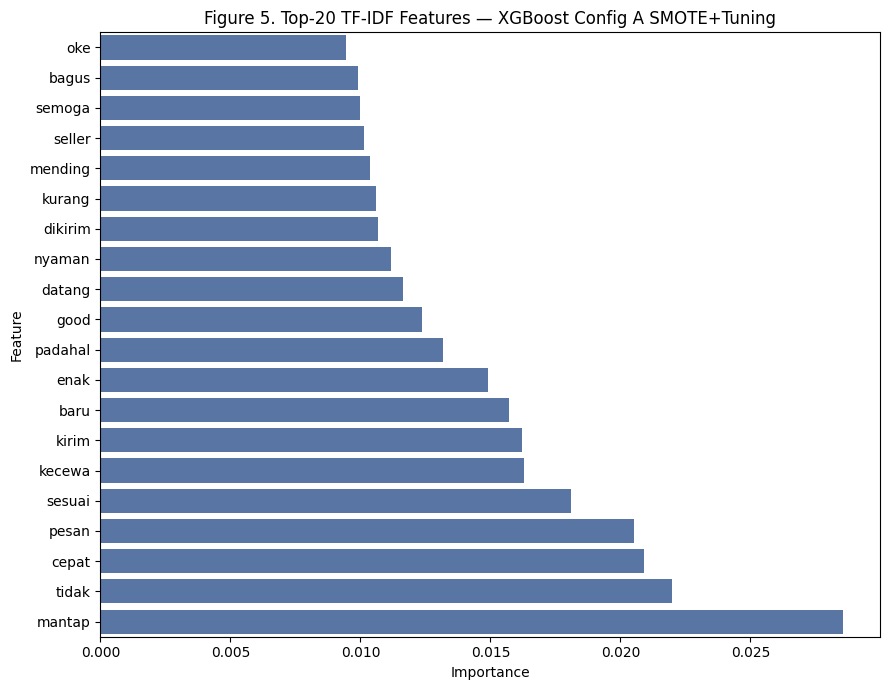

In [43]:
best_xgb_A = best_models["A"]
importances = best_xgb_A.named_steps["clf"].feature_importances_
feat_names_A = configs["A"]["feat_names"]

table5 = pd.DataFrame({
    "Feature": feat_names_A,
    "Importance": importances,
}).sort_values("Importance", ascending=False).head(20).reset_index(drop=True)
table5["Rank"] = table5.index + 1

save_table(table5, "table5_feature_importance")

# Verifikasi eksplisit: kata negasi harus ada, kata fungsi tidak boleh ada
top20_features = set(table5["Feature"])
print("Kata negasi di top-20:", top20_features & NEGATION_WORDS)
print("Kata fungsi murni yang BOCOR ke top-20 (harus kosong):", top20_features & {"di", "nya", "yg", "dan", "yang"})

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=table5.sort_values("Importance"), x="Importance", y="Feature",
            color="#4C72B0", ax=ax)
ax.set_title("Figure 5. Top-20 TF-IDF Features — XGBoost Config A SMOTE+Tuning")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_feature_importance.png"), dpi=150)
plt.show()

In [40]:
# ============================================================
# PHASE 2 — SMOTE-TOMEK VERIFICATION (tambahkan sebelum cell Fase 9)
# ============================================================
print("=== DIAGNOSTIK: Original SMOTE vs SMOTE-Tomek ===\n")

y_train_arr = y_train.values if hasattr(y_train, "values") else y_train

# --- Jalankan Original SMOTE sendiri, catat jumlah sampel ---
smote_only = SMOTE(k_neighbors=5, random_state=RANDOM_STATE)
X_smote, y_smote = smote_only.fit_resample(Xtr_A, y_train_arr)

# --- Jalankan SMOTE-Tomek sendiri, catat jumlah sampel ---
smote_tomek = SMOTETomek(random_state=RANDOM_STATE)
X_smotetomek, y_smotetomek = smote_tomek.fit_resample(Xtr_A, y_train_arr)

print(f"Jumlah sampel training SEBELUM resampling : {Xtr_A.shape[0]} "
      f"(neg={np.sum(y_train_arr==0)}, pos={np.sum(y_train_arr==1)})")
print(f"Jumlah sampel SETELAH Original SMOTE       : {X_smote.shape[0]} "
      f"(neg={np.sum(y_smote==0)}, pos={np.sum(y_smote==1)})")
print(f"Jumlah sampel SETELAH SMOTE-Tomek           : {X_smotetomek.shape[0]} "
      f"(neg={np.sum(y_smotetomek==0)}, pos={np.sum(y_smotetomek==1)})")

n_removed_by_tomek = X_smote.shape[0] - X_smotetomek.shape[0]
print(f"\nJumlah sampel yang DIHAPUS oleh Tomek cleaning: {n_removed_by_tomek}")

if n_removed_by_tomek == 0:
    print("\n>>> KESIMPULAN: SMOTE-Tomek tidak menemukan Tomek links untuk dihapus.")
    print(">>> Hasil identik dengan Original SMOTE adalah VALID, bukan bug.")
    print(">>> Ini masuk akal untuk data dengan separasi kelas yang cukup jelas setelah oversampling,")
    print(">>> atau ketika mayoritas pasangan berdekatan sudah memiliki label yang sama.")
else:
    print(f"\n>>> PERINGATAN: Tomek menghapus {n_removed_by_tomek} sampel, TAPI metrik akhir")
    print(">>> tetap identik dengan Original SMOTE di run sebelumnya. Ini PERLU DISELIDIKI --")
    print(">>> kemungkinan: (a) sampel yang dihapus tidak mempengaruhi decision boundary model,")
    print(">>> (b) ada bug di mana model tidak benar-benar dilatih ulang dengan data baru,")
    print(">>> (c) random_state tidak konsisten antara dua run. Cek pipeline fit ulang secara eksplisit.")

# --- Verifikasi eksplisit: apakah dataset hasil resampling benar-benar identik secara elemen? ---
if X_smote.shape == X_smotetomek.shape:
    are_identical = (X_smote != X_smotetomek).nnz == 0 if hasattr(X_smote, "nnz") else np.array_equal(
        X_smote.toarray() if hasattr(X_smote, "toarray") else X_smote,
        X_smotetomek.toarray() if hasattr(X_smotetomek, "toarray") else X_smotetomek
    )
    print(f"\nDataset hasil SMOTE dan SMOTE-Tomek identik secara elemen: {are_identical}")
else:
    print(f"\nShape berbeda ({X_smote.shape} vs {X_smotetomek.shape}) -- otomatis TIDAK identik secara elemen,")
    print("meski metrik evaluasi akhir bisa saja tetap sama kalau sampel yang dihapus tidak berpengaruh ke model.")

=== DIAGNOSTIK: Original SMOTE vs SMOTE-Tomek ===

Jumlah sampel training SEBELUM resampling : 21131 (neg=305, pos=20826)
Jumlah sampel SETELAH Original SMOTE       : 41652 (neg=20826, pos=20826)
Jumlah sampel SETELAH SMOTE-Tomek           : 41652 (neg=20826, pos=20826)

Jumlah sampel yang DIHAPUS oleh Tomek cleaning: 0

>>> KESIMPULAN: SMOTE-Tomek tidak menemukan Tomek links untuk dihapus.
>>> Hasil identik dengan Original SMOTE adalah VALID, bukan bug.
>>> Ini masuk akal untuk data dengan separasi kelas yang cukup jelas setelah oversampling,
>>> atau ketika mayoritas pasangan berdekatan sudah memiliki label yang sama.

Dataset hasil SMOTE dan SMOTE-Tomek identik secara elemen: True


## Fase 9 — Varian SMOTE (menjawab R2#3 secara PENUH: Original, Borderline, SMOTE-Tomek, SVM-SMOTE)

In [ ]:
SMOTE_VARIANTS = {
    "Original SMOTE": SMOTE(k_neighbors=5, random_state=RANDOM_STATE),
    "Borderline-SMOTE": BorderlineSMOTE(k_neighbors=5, random_state=RANDOM_STATE),
    "SMOTE-Tomek": SMOTETomek(random_state=RANDOM_STATE),
    "SVM-SMOTE": SVMSMOTE(k_neighbors=5, random_state=RANDOM_STATE),
}

XGB_BEST_PARAMS = best_xgb_A.named_steps["clf"].get_params()

smote_variant_rows = []
for variant_name, sampler in SMOTE_VARIANTS.items():
    pipeline = Pipeline([
        ("sampler", sampler),
        ("clf", xgb.XGBClassifier(**{k: v for k, v in XGB_BEST_PARAMS.items()
                                      if k in ["n_estimators", "max_depth", "learning_rate"]},
                                    random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)),
    ])
    pipeline.fit(Xtr_A, y_train)
    y_pred = pipeline.predict(Xte_A)
    metrics = compute_metrics(y_test, y_pred)
    metrics["Variant"] = variant_name
    smote_variant_rows.append(metrics)
    print(f"{variant_name}: Recall(Neg)={metrics['Recall (Neg)']:.4f}, G-Mean={metrics['G-Mean']:.4f}")

table_smote_variant = pd.DataFrame(smote_variant_rows)[
    ["Variant", "Recall (Neg)", "Precision (Neg)", "F1 (Neg)", "G-Mean", "F1 Macro"]
]
save_table(table_smote_variant, "table_smote_variant_comparison")
table_smote_variant

## Fase 10 — Analisis Dimensionalitas & Jarak k-NN (menjawab R2#10 dengan interpretasi yang sesuai data)

Hitung jarak Euclidean antar sampel kelas minoritas untuk beberapa blok fitur, supaya klaim teoretis di manuskrip (curse of dimensionality) punya bukti empiris langsung — dan **interpretasi disesuaikan dengan hasil aktual**, bukan dipaksakan ke narasi "distance concentration" klasik jika datanya menunjukkan sebaliknya.

In [ ]:
def minority_distance_stats(X_matrix, y_labels, block_name, n_dims, sample_cap=500):
    minority_idx = np.where(y_labels.values == 0)[0]
    if len(minority_idx) > sample_cap:
        rng = np.random.RandomState(RANDOM_STATE)
        minority_idx = rng.choice(minority_idx, size=sample_cap, replace=False)
    X_minority = X_matrix[minority_idx]
    X_minority_dense = X_minority.toarray() if hasattr(X_minority, "toarray") else X_minority
    dists = pdist(X_minority_dense, metric="euclidean")
    return {
        "Block": block_name, "n_dims": n_dims,
        "avg_distance": dists.mean(), "std_distance": dists.std(),
        "cv": dists.std() / dists.mean(),
    }, dists

dist_rows = []
dist_raw = {}

for cfg_name in ["A", "C"]:
    stats, raw = minority_distance_stats(configs[cfg_name]["X_train"], y_train,
                                          f"Config {cfg_name}", configs[cfg_name]["X_train"].shape[1])
    dist_rows.append(stats)
    dist_raw[f"Config {cfg_name}"] = raw

table_dimensionality_distance = pd.DataFrame(dist_rows)
save_table(table_dimensionality_distance, "table_dimensionality_distance_analysis")
print(table_dimensionality_distance.to_string(index=False))

interpretation_note = (
    "CATATAN INTERPRETASI (isi manual setelah melihat angka di atas):\n"
    "- Jika CV NAIK seiring dimensi (Config C > Config A): ini BUKAN 'distance concentration' klasik,\n"
    "  melainkan peningkatan heterogenitas/dispersi jarak akibat blok OHE sparse.\n"
    "  Sesuaikan kalimat di Results and Discussion agar tidak mengklaim 'distances converge'.\n"
    "- Jika CV TURUN seiring dimensi: ini sesuai narasi klasik curse of dimensionality, boleh dipertahankan."
)
print(interpretation_note)

fig, ax = plt.subplots(figsize=(8, 5))
for label, raw in dist_raw.items():
    ax.hist(raw, bins=40, alpha=0.5, label=f"{label} ({len(raw)} pairs)")
ax.set_xlabel("Euclidean distance between minority-class samples")
ax.set_ylabel("Frequency (log scale)")
ax.set_title("Pairwise distance distribution: Config A vs Config C")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_distance_distribution.png"), dpi=300)
plt.show()

## Fase 10b — Isolasi Blok (TF-IDF saja vs OHE saja) — memperkuat argumen R2#10

In [ ]:
from scipy.sparse import issparse

def get_block_slice(X_full, feat_names, block_prefixes):
    idx = [i for i, f in enumerate(feat_names) if any(str(f).startswith(p) for p in block_prefixes)]
    return X_full[:, idx], len(idx)

Xtr_C, feat_names_C = configs["C"]["X_train"], configs["C"]["feat_names"]
n_tfidf_dims = configs["A"]["X_train"].shape[1]

X_tfidf_block = Xtr_C[:, :n_tfidf_dims]
X_ohe_block = Xtr_C[:, n_tfidf_dims + len(NUMERIC_COLS):]

block_rows = []
for block_name, X_block in [("TF-IDF block only", X_tfidf_block), ("OHE block only", X_ohe_block)]:
    stats, _ = minority_distance_stats(X_block, y_train, block_name, X_block.shape[1])
    block_rows.append(stats)

table_block_distance_isolation = pd.DataFrame(block_rows)
save_table(table_block_distance_isolation, "table_block_distance_isolation")
table_block_distance_isolation

## Fase 11 — Eksplorasi N-gram (menjawab R2#8)

In [ ]:
tfidf_bigram = TfidfVectorizer(max_features=1000, ngram_range=(1, 2), stop_words=list(STOPWORDS_FINAL))
Xtr_bigram = tfidf_bigram.fit_transform(X_train[TEXT_COL])
Xte_bigram = tfidf_bigram.transform(X_test[TEXT_COL])

metrics_bigram, _, _ = run_smote_tuning_xgb(Xtr_bigram, y_train, Xte_bigram, y_test)
metrics_unigram = table3[(table3["Configuration"] == "Config A") & (table3["Condition"] == "SMOTE+Tuning")].iloc[0].to_dict()

table_ngram_comparison = pd.DataFrame([
    {"Feature Type": "Unigram only (Config A)", **{k: metrics_unigram[k] for k in
        ["Accuracy", "Recall (Neg)", "Precision (Neg)", "F1 (Neg)", "F1 Macro", "G-Mean"]}},
    {"Feature Type": "Unigram + Bigram", **metrics_bigram},
])
save_table(table_ngram_comparison, "table_ngram_comparison")
table_ngram_comparison

## Fase 12 — Confusion Matrix untuk Semua Konfigurasi x Kondisi

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
plot_configs = [
    ("A", "Baseline", model_base if False else None),  # placeholder digantikan loop di bawah
]

idx = 0
for row_i, condition in enumerate(["Baseline", "SMOTE+Tuning"]):
    for col_i, cfg_name in enumerate(["A", "B", "C"]):
        ax = axes[row_i, col_i]
        Xte = configs[cfg_name]["X_test"]
        if condition == "Baseline":
            model = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)
            model.fit(configs[cfg_name]["X_train"], y_train)
            y_pred = model.predict(Xte)
        else:
            y_pred = best_models[cfg_name].predict(Xte)
        cm = confusion_matrix(y_test, y_pred)
        ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(ax=ax, colorbar=False)
        ax.set_title(f"Config {cfg_name} — {condition}")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_confusion_matrix_combined.png"), dpi=300)
plt.show()

In [38]:
import sys
import sklearn
import imblearn
import xgboost
import lightgbm
import catboost
import scipy
import statsmodels
import pandas
import numpy

print("Python", sys.version.split()[0])

for m in [
    numpy,
    pandas,
    sklearn,
    imblearn,
    xgboost,
    lightgbm,
    catboost,
    scipy,
    statsmodels
]:
    print(f"{m.__name__}=={m.__version__}")

Python 3.13.18
numpy==2.4.6
pandas==2.2.3
sklearn==1.6.1
imblearn==0.14.2
xgboost==3.4.1
lightgbm==4.6.0
catboost==1.2.10
scipy==1.16.3
statsmodels==0.15.0


## Fase 13 — Konsolidasi & Unduh Semua Tabel Final

Ringkasan seluruh tabel yang sudah dihasilkan di `/content/final_results/` — inilah SATU-SATUNYA sumber angka yang boleh dipakai untuk revisi manuskrip.

In [ ]:
import shutil

final_tables = sorted([f for f in os.listdir(OUTPUT_DIR) if f.endswith(".csv")])
print("=== Tabel final yang tersedia ===")
for f in final_tables:
    print(" -", f)

print("\n=== Figure final yang tersedia ===")
for f in sorted(os.listdir(FIG_DIR)):
    print(" -", f)

# Zip semua hasil untuk diunduh
shutil.make_archive("/content/joscex_final_results", "zip", OUTPUT_DIR)
print("\nSemua hasil di-zip: /content/joscex_final_results.zip")

from google.colab import files
files.download("/content/joscex_final_results.zip")

## Fase 14 — Checklist Konsistensi Sebelum Menulis Manuskrip

Jalankan sel ini terakhir sebagai sanity check otomatis sebelum angka dipakai di Word.

In [ ]:
print("=== SANITY CHECK ===\n")

# 1. Cek recall Config A SMOTE+Tuning konsisten dengan Table 5 (model yang sama dipakai)
recall_table3 = table3[(table3["Configuration"]=="Config A") & (table3["Condition"]=="SMOTE+Tuning")]["Recall (Neg)"].iloc[0]
recall_model_comparison = table_baseline_model_comparison[table_baseline_model_comparison["Model"]=="XGBoost"]["Recall (Neg)"].iloc[0]
print(f"1. Recall XGBoost Table 3           : {recall_table3:.4f}")
print(f"   Recall XGBoost Model Comparison   : {recall_model_comparison:.4f}")
print(f"   Konsisten? {'YA' if abs(recall_table3 - recall_model_comparison) < 1e-9 else 'TIDAK -- PERIKSA ULANG'}")

# 2. Cek apakah recall XGBoost vs model lain identik (tie) - beri catatan bukan alarm otomatis
print(f"\n2. Perbandingan recall antar model (Config A, SMOTE+Tuning):")
print(table_baseline_model_comparison[["Model", "Recall (Neg)"]].to_string(index=False))
print("   Catatan: dengan n=76 sampel negatif, hanya ada 77 nilai recall diskret yang mungkin -")
print("   kesamaan recall antar model TIDAK otomatis mencurigakan, tapi tetap layak disebutkan di teks.")

# 3. Cek stopword list konsisten dipakai di semua config
print(f"\n3. Kata negasi di top-20 feature importance: {top20_features & NEGATION_WORDS}")
print(f"   Kata fungsi murni di top-20 (harus kosong): {top20_features & {'di','nya','yg','dan','yang'}}")

# 4. Ringkasan arah temuan repeated CV vs single split
print(f"\n4. Perbandingan XGBoost vs LR:")
print(f"   Single-split  -> XGBoost: {table3[(table3.Configuration=='Config A')&(table3.Condition=='SMOTE+Tuning')]['Recall (Neg)'].iloc[0]:.4f} | LR: cek table_baseline_model_comparison")
xgb_cv = table_repeated_cv[(table_repeated_cv.Model=="XGBoost") & (table_repeated_cv.Metric=="Recall (Neg)")]["Mean"].iloc[0]
lr_cv = table_repeated_cv[(table_repeated_cv.Model=="Logistic Regression") & (table_repeated_cv.Metric=="Recall (Neg)")]["Mean"].iloc[0]
print(f"   Repeated CV   -> XGBoost: {xgb_cv:.4f} | LR: {lr_cv:.4f}")
print(f"   >>> Jika arahnya berbeda antara single-split dan repeated CV, PUTUSKAN dulu klaim mana")
print(f"       yang dipakai di Abstract/Conclusion sebelum menulis manuskrip. <<<")

print("\n=== Sanity check selesai. Review manual tetap diperlukan sebelum finalisasi. ===")